# Disarm (Mercenary)

Disarm is a passive. Every landed melee hit has a **10% chance** to weaken the defender's grip:
their **Weapon Skill** drops for 45 s. From a modified skill of 100, the proc also hits
adjacent enemies attacking the Mercenary, if they fail a resist roll.

Weapon Skill is the fight skill used for **both attack and defence** (`get_fight_skill`), so one
proc moves the melee hit table in the Mercenary's favour in both directions. The defender misses
more, and the Mercenary hits more often and harder.

**Rebalanced.** The penalty used to be `clamp(3⌊p'/2⌋, 3, 150)`. It reached its 150 ceiling at
skill 96, below the Mercenary raise cap of 120, so the rest of the skill growth did nothing. It
now follows the shared mod-300 knee: `knee_300(p', 0, 150)`, which is $p'/2$ up to 300 and half
that slope beyond. The endgame value (about 150) is unchanged. The slope is a third of before, so
the raise cap gives 63 instead of 150. There is no hard limit because Weapon Skill floors at 1.
The "before" curves below show the old formula.

| | |
|---|---|
| Class | Mercenary |
| Trigger | 10% per landed, undodged primary melee hit (`disarm_on_hit`), only if `skill[SK_DISARM][0] != 0` |
| Target | Defender; at raw skill ≥ 100 also the caster's 4 cross neighbours that are attacking the caster |
| Cost | none |
| Landing roll | primary: none. Splash: $p + \text{rand}(20) > R + \text{rand}(20)$ |
| Duration | 45 s; every new proc replaces the old item and restarts the timer |
| Effect | `skill[SK_WEAPON][1] += −max(3, knee_300(p', 0, 150))`: 63 at the raise cap, 150 near skill 300, no limit (Weapon Skill floors at 1) |
| Source | `server/src/driver/skill/mercenary.rs::disarm_on_hit`, `apply_disarm`; `skill_knee_300` in `server/src/driver/skill/common.rs`; hit table in `server/src/state/combat.rs::do_attack` |

---

# Formula

With immunity $I$ and caster race multiplier $r$ (1.05 for a Mercenary):

$$
p' = \lfloor r\cdot\text{imm}(p, I)\rfloor
\qquad
\text{penalty} = \max\!\left(3,\ \text{knee}_{300}(p', 0, 150)\right)
= \begin{cases}
\max\!\left(3,\ \lfloor p'/2 \rfloor\right) & p' \le 300 \\
150 + \lfloor (p' - 300)/4 \rfloor & p' > 300
\end{cases}
$$

Before: $\operatorname{clamp}\!\left(3\lfloor p'/2 \rfloor,\ 3,\ 150\right)$.

The melee roll is a d20 against a chance taken from the difference $\Delta$ between attacker and
defender Weapon Skill. Selected rows:

| $\Delta$ | −41 or less | −40 | −30 | −20 | 0 | +20 | +30 | +40 or more |
|---|---|---|---|---|---|---|---|---|
| hit on d20 ≤ | 1 | 2 | 4 | 7 | 12 | 18 | 19 | 19 |
| damage bonus | −16 / −32 / −64 | −8 | −2 | 0 | 0 | +3 | +5 | +20 |

A penalty $D$ on the defender adds $D$ to the Mercenary's $\Delta$ and subtracts $D$ from the
defender's $\Delta$ against **everyone**. A penalty of 41 or more pins both ends of the table
against an equal opponent. Against an enemy with $a$ more Weapon Skill it takes $a + 41$.

Breakpoints for a Mercenary caster at immunity 0:

| Quantity | Now | Before |
|---|---|---|
| Floor of 3 | skill ≤ 7 | skill ≤ 3 |
| Penalty ≥ 41 (pins an equal opponent) | skill 79 | skill 27 |
| At skill 100 (AoE unlocks) | 52 | 150 |
| At the raise cap (skill 120) | 63 | 150 |
| At skill 275 / 300 | 144 / 153 | 150 |
| Reaches 150 | skill 286 | skill 96 |
| At skill 350 / 450 | 166 / 193 | 150 |
| Limit | none (Weapon Skill floors at 1) | 150 |
| AoE threshold | raw modified skill ≥ 100 (immunity and race are not applied to this check) | same |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
DURATION_S = 45
PROC = 0.10
AOE_MIN = 100

# Model

In [ ]:
def disarm_power(p, immun=0, race="Mercenary"):
    return mm.spell_power(p, immun, race)


def disarm_penalty(p, immun=0, race="Mercenary"):
    return mm._scalar(np.maximum(mm.knee_300(disarm_power(p, immun, race), 0, 150), 3))


# Before the rebalance: 3 per 2 points of p', clamped to 3..150 (150 from skill 96).
def old_disarm_penalty(p, immun=0, race="Mercenary"):
    return mm.clamp(mm.idiv(disarm_power(p, immun, race), 2) * 3, 3, 150)


def outcome(penalty, adv=0, merc_ws=100):
    """(Mercenary hit chance, bonus, enemy hit chance, bonus) against an enemy with
    Weapon Skill `merc_ws + adv` that carries the given Disarm penalty."""
    enemy = np.maximum(1, merc_ws + adv - np.asarray(penalty))
    mc, mb = mm.melee_hit_table(merc_ws - enemy)
    ec, eb = mm.melee_hit_table(enemy - merc_ws)
    return mm._scalar(np.asarray(mc) / 20), mb, mm._scalar(np.asarray(ec) / 20), eb


def hit_chances(p, adv=0, immun=0, penalty=disarm_penalty):
    """(Mercenary hit chance, enemy hit chance) once the enemy is disarmed."""
    mc, _, ec, _ = outcome(penalty(p, immun), adv)
    return mc, ec


def p_splash(p, resist, pen_pct=0):
    return np.where(np.asarray(p) >= AOE_MIN, mm.p_opposed_d20(p, mm.effective_resist(resist, pen_pct)), 0.0)


def p_disarmed_by(t, landed_per_s):
    """P(at least one proc within t seconds) at a steady rate of landed hits."""
    return 1 - (1 - PROC) ** np.floor(np.asarray(t) * landed_per_s)

# Validation

`disarm_penalises_weapon_skill_for_45_seconds` uses a race-neutral caster and immunity 0:

- raw power 40 → penalty 20, and `active == TICKS*45`;
- power 1 → 3 (the floor);
- power 300 → 150;
- power 500 → 200 (half slope past 300, no limit).

`skill_knee_300_is_linear_to_the_knee_then_half_slope` checks the shared helper that
`mm.knee_300` ports.

In [ ]:
assert disarm_penalty(40, race="Other") == 20
assert disarm_penalty(1, race="Other") == 3
assert disarm_penalty(300, race="Other") == 150
assert disarm_penalty(500, race="Other") == 200
assert mm.TICKS * DURATION_S == 1620
assert [mm.knee_300(p, 30, 75) for p in (-5, 0, 150, 300, 350, 450)] == [30, 30, 52, 75, 78, 86]
assert mm.knee_300(600, 0, 600) == 900

# Mercenary caster (race 1.05), immunity 0.
assert disarm_penalty(7) == 3 and disarm_penalty(8) == 4
assert disarm_penalty(78) == 40 and disarm_penalty(79) == 41
assert [int(disarm_penalty(p)) for p in (100, 120, 275, 300, 350, 450)] == [52, 63, 144, 153, 166, 193]
assert disarm_penalty(285) == 149 and disarm_penalty(286) == 150

# Before: 60 / 3 / 150 for the same test powers, 150 from skill 96.
assert old_disarm_penalty(40, race="Other") == 60
assert old_disarm_penalty(1, race="Other") == 3 and old_disarm_penalty(500, race="Other") == 150
assert old_disarm_penalty(3) == 3 and old_disarm_penalty(4) == 6
assert old_disarm_penalty(26) == 39 and old_disarm_penalty(27) == 42
assert old_disarm_penalty(95) == 147 and old_disarm_penalty(96) == 150

assert mm.melee_hit_table(0) == (12, 0) and mm.melee_hit_table(40) == (19, 20)
assert mm.melee_hit_table(-30) == (4, -2) and mm.melee_hit_table(-41) == (1, -16)
print("Disarm model OK")

# Plots

In [ ]:
fig, ax = plt.subplots()
sat = []
for immun in mm.IMMUNITY_SWEEP:
    v = disarm_penalty(P, immun)
    line, = ax.plot(P, v, label=f"target immunity {immun}")
    ax.plot(P, old_disarm_penalty(P, immun), color=line.get_color(), lw=1.2, ls=":")
    sat.append(int(P[np.argmax(v >= 150)]) if np.any(v >= 150) else None)
ax.plot([], [], color="grey", lw=1.2, ls=":", label="before (same colours)")
mm.skill_axis(ax, "Weapon Skill removed", "Disarm penalty (Mercenary caster)")
mm.mark_caps(ax, extra=[(96, "old 150 at 96"), (sat[0], "150 at 286")])
ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.85), fontsize=9)
print("skill at which the penalty reaches 150, by immunity:", dict(zip(mm.IMMUNITY_SWEEP, sat)))
for s in (mm.RAISE_CAP_MERC, *mm.ENDGAME, 350):
    print(f"skill {s}: penalty by immunity", {i: int(disarm_penalty(s, i)) for i in mm.IMMUNITY_SWEEP},
          "before", {i: int(old_disarm_penalty(s, i)) for i in mm.IMMUNITY_SWEEP})

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
advantages = (0, 40, 80, 120)

for ax, idx, ylabel, title in (
    (axes[0], 1, "P(enemy hits the Mercenary)", "Enemy hit chance while disarmed"),
    (axes[1], 0, "P(Mercenary hits)", "Mercenary hit chance vs a disarmed enemy"),
):
    for adv in advantages:
        line, = ax.plot(P, hit_chances(P, adv)[idx], label=f"enemy Weapon Skill +{adv}")
        ax.plot(P, hit_chances(P, adv, penalty=old_disarm_penalty)[idx], color=line.get_color(),
                lw=1.2, ls=":")
    ax.plot([], [], color="grey", lw=1.2, ls=":", label="before (same colours)")
    mm.skill_axis(ax, ylabel, title)
    ax.set_ylim(0, 1.05)
    mm.mark_caps(ax)
axes[0].legend(loc="center right", fontsize=9)
axes[1].legend(loc="center right", fontsize=9)
plt.tight_layout()

print("Mercenary hit % / bonus, enemy hit % / bonus, by the enemy's Weapon Skill advantage")
for label, pen in (("skill 120 before", old_disarm_penalty(120)), ("skill 120", disarm_penalty(120)),
                   ("skill 275", disarm_penalty(275)), ("skill 300", disarm_penalty(300)),
                   ("skill 350", disarm_penalty(350))):
    cells = []
    for adv in (0, 20, 40, 60, 90, 120):
        mc, mb, ec, eb = outcome(pen, adv)
        cells.append(f"+{adv}: {mc:.0%}/{mb:+d} {ec:.0%}/{eb:+d}")
    print(f"{label:>17} (penalty {int(pen):>3}) | " + " | ".join(cells))

Without Disarm, an evenly matched pair hits each other 60% of the time. At the raise cap 120
(penalty 63) Disarm still pins both ends of the table against an enemy with up to +22 Weapon
Skill: the enemy hits 5% of the time and the Mercenary 95% with +20 damage. Against +60 it now
turns 95/5 (enemy/Mercenary hit chance) into 55/65 with no damage bonus either way; before it
gave 5/95. At the endgame (penalty 144–153) both ends stay pinned up to +103–+112, close to the
old ceiling's +109.

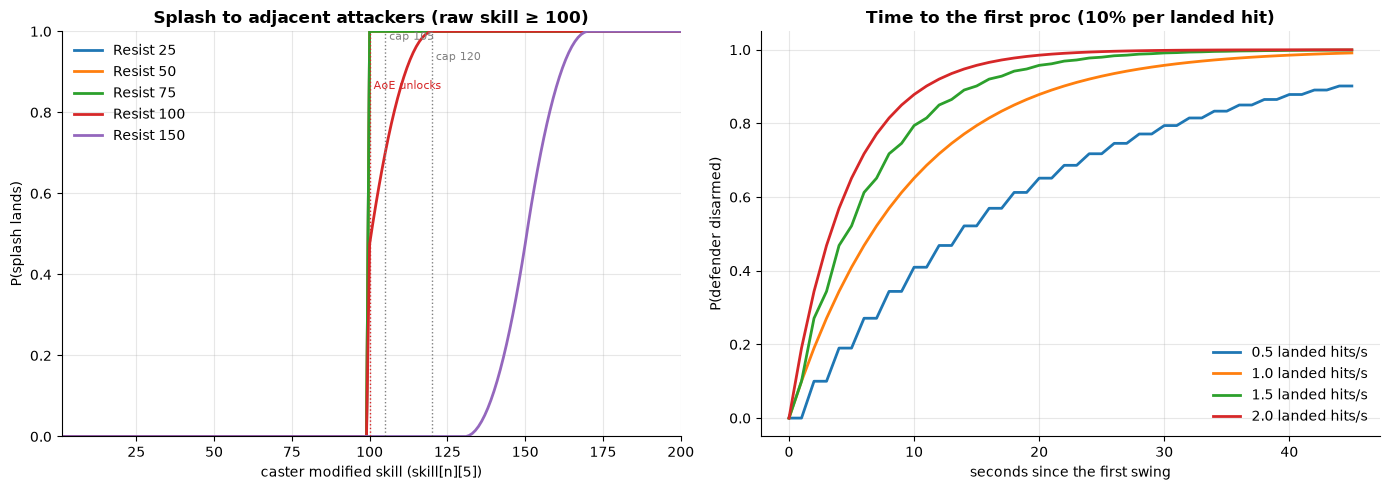

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for resist in mm.RESIST_SWEEP:
    ax.plot(P, p_splash(P, resist), label=f"Resist {resist}")
mm.skill_axis(ax, "P(splash lands)", "Splash to adjacent attackers (raw skill ≥ 100)")
ax.set_ylim(0, 1)
mm.mark_caps(ax, extra=[(AOE_MIN, "AoE unlocks")])
ax.legend()

ax = axes[1]
t = np.arange(0, 46)
for landed in (0.5, 1.0, 1.5, 2.0):
    ax.plot(t, p_disarmed_by(t, landed), label=f"{landed} landed hits/s")
ax.set_xlabel("seconds since the first swing")
ax.set_ylabel("P(defender disarmed)")
ax.set_title("Time to the first proc (10% per landed hit)")
ax.legend()
plt.tight_layout()

# Observations

- **Still one of the strongest passives, but now it grows to the endgame.** The penalty is 63 at
  the raise cap 120 (before: 150), 144 at skill 275 and 153 at 300. It passes the old 150 ceiling
  at skill 286 (before: 96). Skill 350 adds 13 more (166), which keeps the table pinned against
  an enemy with 13 more Weapon Skill.
- **The mid-game is much weaker.** An equal opponent is pinned (enemy 5%, Mercenary 95% with +20
  damage) from skill 79 (before: 27). At the raise cap the pin holds up to an enemy advantage of
  +22. Against +40 the Mercenary hits 90% with +3 and the enemy 30%; against +60, 65% and 55%.
  Before, any Disarm from skill 96 pinned the table up to +109.
- **Immunity matters more in the mid-game.** At skill 120 the penalty drops from 63 to 36 at
  target immunity 100 (before: 150 and 108). At skill 300 it is 131 at immunity 100.
- **Uptime is close to 100% after the first proc.** Each landed hit re-procs at 10% and resets the
  45 s timer. At 1.2 landed hits per second (about 2 swings/s at 60% to hit), the first proc
  comes after about 8 s on average. Once applied, the chance of no new proc in 45 s is 0.3%.
- **It helps everyone attacking the target.** The penalty lowers the defender's Weapon Skill
  itself, so allies hitting the same enemy, and anyone the enemy attacks, also benefit.
- **The splash is gated on raw skill, not power.** The `power < 100` check uses the raw modified
  skill, while the penalty uses $p'$. Immunity therefore never disables the splash, but it weakens
  the penalty every splash target receives. At skill 100 each splash target loses 52 Weapon Skill
  (before: 150). Splash targets roll the opposed d20 with raw skill: at skill 100 the splash lands
  47.5% of the time on Resist 100 and never on Resist 120 or more. At skill 300 it always lands on
  Resist 275 and 47.5% of the time on Resist 300.
- **Open: the endgame size.** The slope now matches the earlier suggestion of $p'/2$, so the
  early saturation is gone. The endgame value is unchanged, though: at skill 300 one proc still
  pins the hit table for any enemy within 112 Weapon Skill. If that is too strong, lower the
  300 value. `knee_300(p', 0, 80)` would give 33 at the raise cap and 82 at skill 300 (pinned up
  to +41).